# 7 - Ensemble interaction-graph analysis: 12 PCW and 17 PCW


| Analysis | Model source | Separate output |
|---|---|---|
| 12 PCW | `../Results/Boolean_network_sampling_Tcell_12w_vs_17w/core/12w/bn*.bnet` | `../Results/Ensemble_analysis_Tcell_12w_vs_17w/12w/` |
| 17 PCW | `../Results/Boolean_network_sampling_Tcell_12w_vs_17w/core/17w/bn*.bnet` | `../Results/Ensemble_analysis_Tcell_12w_vs_17w/17w/` |



## 1. Locate the week-specific SCC ensembles

The model count is read from each `model_manifest.csv`, **not assumed to be 50**. Incomplete sampling runs can still be analyzed and are flagged. Model hashes and the expected SCC gene list are checked before processing.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from itertools import product
import hashlib
import json
import re

import pandas as pd
import mpbn
import graphviz
from IPython.display import display

WEEKS = ('12w', '17w')
LABELS = {'12w': '12 PCW', '17w': '17 PCW'}
RESULTS = Path('../Results')
SAMPLE_ROOT = RESULTS / 'Boolean_network_sampling_Tcell_12w_vs_17w' / 'core'
COMPONENT_ROOT = RESULTS / 'Component_analysis_Tcell_12w_vs_17w'
OUTPUT_ROOT = RESULTS / 'Ensemble_analysis_Tcell_12w_vs_17w'
SHOW_GRAPHS_INLINE = True

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
FOLDERS = {week: SAMPLE_ROOT / week for week in WEEKS}
for week, folder in FOLDERS.items():
    if not folder.is_dir():
        raise FileNotFoundError(f'{LABELS[week]} models are missing: {folder}. Run notebook 6 first.')
print('Input:', SAMPLE_ROOT)
print('Output:', OUTPUT_ROOT)

ipylab module is not installed, menus and toolbar are disabled.


Input: ../Results/Boolean_network_sampling_Tcell_12w_vs_17w/core
Output: ../Results/Ensemble_analysis_Tcell_12w_vs_17w


## 2. Validate the saved ensembles

In [2]:
def file_sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def model_sort_key(path):
    match = re.fullmatch(r'bn(\d+)\.bnet', path.name)
    return int(match.group(1)) if match else float('inf')


def load_ensemble(week):
    folder = FOLDERS[week]
    manifest_path = folder / 'model_manifest.csv'
    metadata_path = folder / 'run_metadata.json'
    genes_path = folder / 'modeled_genes.txt'
    for required in (manifest_path, metadata_path, genes_path):
        if not required.is_file():
            raise FileNotFoundError(f'{week}: missing sampling output {required}')

    run = json.loads(metadata_path.read_text(encoding='utf-8'))
    if run.get('week') != week or run.get('network_level') != 'largest_scc':
        raise ValueError(f'{week}: this analysis accepts only that week\'s largest-SCC ensemble')
    if run.get('required_fixed_points') != ['S4']:
        raise ValueError(f'{week}: run metadata does not specify the required S4 fixed point')
    if not run.get('positive_reachability'):
        raise ValueError(f'{week}: missing positive reachability provenance')

    expected_genes = {line.strip().upper() for line in genes_path.read_text(encoding='utf-8').splitlines() if line.strip()}
    if not expected_genes or len(expected_genes) != int(run['modeled_gene_count']):
        raise ValueError(f'{week}: expected SCC gene list/count mismatch')
    component_genes = COMPONENT_ROOT / week / 'core_genes.txt'
    if component_genes.is_file():
        exported = {line.strip().upper() for line in component_genes.read_text(encoding='utf-8').splitlines() if line.strip()}
        if exported != expected_genes:
            raise ValueError(f'{week}: sampled SCC genes differ from component-analysis SCC genes')
    component_sif = COMPONENT_ROOT / week / 'synthesis_core_network.sif'
    if component_sif.is_file() and file_sha256(component_sif) != run.get('input_sif_sha256'):
        raise ValueError(f'{week}: source SCC SIF differs from that used in sampling')

    manifest = pd.read_csv(manifest_path, keep_default_na=False)
    fields = {'week', 'model_id', 'filename', 'sha256', 'size_bytes'}
    if not fields.issubset(manifest.columns):
        raise ValueError(f'{week}: missing columns in model_manifest.csv: {sorted(fields-set(manifest.columns))}')
    manifest = manifest.sort_values('model_id').reset_index(drop=True)
    files = sorted(folder.glob('bn*.bnet'), key=model_sort_key)
    if len(files) != len(manifest):
        raise ValueError(f'{week}: manifest contains {len(manifest)} entries but directory contains {len(files)} models')
    if not files:
        raise RuntimeError(f'{week}: no saved models yet; run the sampling notebook first')

    seen_hashes = set()
    for i, row in manifest.iterrows():
        name = f'bn{i:04d}.bnet'
        path = folder / name
        if (str(row['week']) != week or int(row['model_id']) != i
                or str(row['filename']) != name or files[i] != path):
            raise ValueError(f'{week}: unexpected model ordering or filename in manifest row {i}')
        digest = file_sha256(path)
        if str(row['sha256']) != digest or int(row['size_bytes']) != path.stat().st_size:
            raise ValueError(f'{week}: checksum or size mismatch in {name}')
        if digest in seen_hashes:
            raise ValueError(f'{week}: duplicate saved models detected: {name}')
        seen_hashes.add(digest)

    if len(files) != int(run.get('number_saved', -1)):
        raise ValueError(f'{week}: run_metadata.json and manifest disagree about model count')
    return {
        'files': files, 'run': run, 'genes': expected_genes,
        'complete': bool(run.get('status') == 'complete'),
        'requested': int(run['number_requested']),
        'folder': folder,
    }

ENSEMBLES = {week: load_ensemble(week) for week in WEEKS}
for week, item in ENSEMBLES.items():
    print(f"{LABELS[week]}: {len(item['files'])}/{item['requested']} unique SCC models; "
          f"{len(item['genes'])} genes; status={item['run'].get('status')}")
    if not item['complete']:
        print(f'  NOTE: {LABELS[week]} ensemble is incomplete. Frequencies use the saved model count.')

12 PCW: 50/50 unique SCC models; 8 genes; status=complete
17 PCW: 50/50 unique SCC models; 10 genes; status=complete


## 3. Count Boolean functions and signed influences

Each signed source-to-target influence is counted **at most once per model**.

For function variability, models are compared using the same Boolean truth table over each rule's regulators, rather than comparing implementation-specific internal Boolean-function IDs. A node may be constant in some models and nonconstant in others. Graph edges represent **influences present in sampled rules**, not necessarily every edge available in the prior SCC influence graph.

In [3]:
def dnf_signature_and_influences(clauses):
    # mpbn.minibn.struct_of_dnf returns an iterable of AND clauses; the
    # function is the OR of these conjunctions.
    terms = []
    for conjunction in clauses:
        terms.append(tuple(sorted((str(gene).upper(), bool(sign)) for gene, sign in conjunction)))
    regulators = tuple(sorted({gene for term in terms for gene, _ in term}))
    signs_used = {(gene, sign) for term in terms for gene, sign in term}
    truth_table = []
    for values in product((False, True), repeat=len(regulators)):
        state = dict(zip(regulators, values))
        active = any(all(state[gene] == sign for gene, sign in term) for term in terms)
        truth_table.append(int(active))
    # Function signature is invariant to syntactic presentation of the same DNF.
    return (regulators, tuple(truth_table)), signs_used


def analyze_models(week, ensemble):
    functions = defaultdict(set)
    constant_counts = defaultdict(Counter)
    influence_counts = defaultdict(lambda: defaultdict(Counter))
    model_gene_set = ensemble['genes']

    for file in ensemble['files']:
        model = mpbn.MPBooleanNetwork(str(file))
        genes = {str(gene).upper() for gene in model.keys()}
        if genes != model_gene_set:
            raise ValueError(f'{week}: {file.name} has unexpected genes: '
                             f'missing={sorted(model_gene_set-genes)}, extra={sorted(genes-model_gene_set)}')
        for target in model.keys():
            name = str(target).upper()
            rule = model[target]
            if rule is True or rule == True:
                functions[name].add(('CONST', 1))
                constant_counts[name][True] += 1
                continue
            if rule is False or rule == False:
                functions[name].add(('CONST', 0))
                constant_counts[name][False] += 1
                continue

            clauses = mpbn.minibn.struct_of_dnf(model.ba, rule)
            signature, signed_regulators = dnf_signature_and_influences(clauses)
            functions[name].add(('TABLE', signature))
            for regulator, sign in signed_regulators:
                if regulator not in model_gene_set:
                    raise ValueError(f'{week}: {file.name}: {regulator} regulates {name} but is outside the SCC')
                influence_counts[name][regulator][sign] += 1

    return {
        'week': week, 'files': ensemble['files'], 'n_models': len(ensemble['files']),
        'genes': sorted(model_gene_set), 'functions': functions,
        'constants': constant_counts, 'influences': influence_counts,
    }

STATS = {week: analyze_models(week, ENSEMBLES[week]) for week in WEEKS}
for week, stats in STATS.items():
    invariant = sum(len(stats['functions'][gene]) == 1 for gene in stats['genes'])
    print(f'{LABELS[week]}: {stats["n_models"]} models, {len(stats["genes"])} genes, {invariant} invariant genes')

12 PCW: 50 models, 8 genes, 3 invariant genes
17 PCW: 50 models, 10 genes, 3 invariant genes


## 4. Create each week's interaction graph

Node labels give distinct Boolean functions, rectangles indicate genes constant in at least one model, and edge labels give the number of sampled networks containing that signed influence. Green arrows indicate activation; red T-ended arrows indicate inhibition. Darker/thicker edges recur in more models. Counts always use the actual number sampled **within that week**.

In [4]:
def get_arcs_size(values, min_intensity=1, max_intensity=8):
    # Keep the original frequency-to-line-width mapping.
    result = {}

    def assign(parts, low, high, left=False):
        if not parts:
            return
        gaps = [parts[i + 1] - parts[i] for i in range(len(parts) - 1)]
        if not gaps or max(gaps) == 0 or low == high:
            for number in parts:
                result[number] = str(low if left else high)
            return
        split = gaps.index(max(gaps))
        middle = (low + high) // 2
        assign(parts[:split + 1], low, middle, True)
        assign(parts[split + 1:], middle + 1, high)

    assign(sorted(set(values)), min_intensity, max_intensity)
    return result


def create_influence_graph(stats):
    n_models = stats["n_models"]
    functions = stats["functions"]
    constants = stats["constants"]
    influences = stats["influences"]

    counts = [
        number
        for targets in influences.values()
        for signs in targets.values()
        for number in signs.values()
    ]
    widths = get_arcs_size(counts)
    widths[n_models] = "13"  # Highlight influences found in every model.

    dot = graphviz.Digraph("models_per_edge", comment="Number of models containing each regulatory influence")
    dot.graph_attr.update(rankdir="LR", overlap="false", splines="true", bgcolor="white")

    for gene in stats["genes"]:
        n_functions = len(functions[gene])
        if n_functions == 1:
            fill, style, fontsize = "darkgoldenrod2", "rounded,filled,bold", "22"
        elif n_functions == 2:
            fill, style, fontsize = "lightgoldenrod1", "rounded,filled", "19"
        elif n_functions == 3:
            fill, style, fontsize = "cornsilk", "rounded,filled", "18"
        elif n_functions < 10:
            fill, style, fontsize = "white", "rounded,filled", "17"
        else:
            fill, style, fontsize = "white", "rounded,filled,dotted", "17"

        label = f"{gene}\n{n_functions} funcs"
        if gene in constants:
            # Show both constant values if they occur among the models.
            for val in (False, True):
                if constants[gene][val]:
                    label += f"\n{int(val)}: {constants[gene][val]}"

        dot.node(
            gene, label=label, shape="box" if gene in constants else "oval",
            fillcolor=fill, style=style, fontsize=fontsize,
            fontcolor="black", fontname="Arial",
        )

    for target, sources in influences.items():
        for source, signs in sources.items():
            for positive, number in signs.items():
                universal = number == n_models
                dot.edge(
                    source, target, label=str(number),
                    penwidth=widths[number],
                    color=("darkgreen" if universal else "darkolivegreen3") if positive else ("firebrick" if universal else "lightcoral"),
                    fontcolor=("darkgreen" if universal else "darkolivegreen3") if positive else ("firebrick" if universal else "lightcoral"),
                    arrowhead="normal" if positive else "tee",
                    fontname="Arial", fontsize="17",
                    arrowsize="0.8" if positive else "1.0",
                )
    return dot

## 5. Export a separate figure and statistics for each week

Each output folder contains `IGstat.pdf`, `IGstat.gv`, `node_function_variability.csv`, `invariant_genes.csv`, `edge_frequencies.csv`, `edge_occurrence_summary.csv`, and `summary.json`. The model manifest is **not** changed. The figure can also be displayed inline.

In [5]:
def save_ensemble_results(stats, output_folder):
    output_folder.mkdir(parents=True, exist_ok=True)
    n_models = stats["n_models"]

    gene_rows = []
    for gene in stats["genes"]:
        gene_rows.append({
            "gene": gene,
            "distinct_boolean_functions": len(stats["functions"][gene]),
            "constant_0_models": stats["constants"][gene][False],
            "constant_1_models": stats["constants"][gene][True],
        })
    gene_df = pd.DataFrame(gene_rows)
    gene_df.to_csv(output_folder / "node_function_variability.csv", index=False)
    gene_df.loc[gene_df["distinct_boolean_functions"] == 1].to_csv(
        output_folder / "invariant_genes.csv", index=False
    )

    edge_rows = []
    for target, sources in stats["influences"].items():
        for source, signs in sources.items():
            for positive, count in signs.items():
                edge_rows.append({
                    "source": source,
                    "target": target,
                    "influence": "activation" if positive else "inhibition",
                    "n_models": count,
                    "percent_models": round(100 * count / n_models, 2),
                })

    edge_columns = ["source", "target", "influence", "n_models", "percent_models"]
    edge_df = pd.DataFrame(edge_rows, columns=edge_columns)
    edge_df.to_csv(output_folder / "edge_frequencies.csv", index=False)

    # Save the count-by-frequency summary printed by the original notebook.
    frequencies = Counter(edge_df["n_models"])
    frequency_df = pd.DataFrame([
        {"n_models_with_edge": frequency, "n_edges": count}
        for frequency, count in sorted(frequencies.items())
    ], columns=["n_models_with_edge", "n_edges"])
    frequency_df.to_csv(output_folder / "edge_occurrence_summary.csv", index=False)

    dot = create_influence_graph(stats)
    # Keep both the .gv source and the PDF inside the requested output folder.
    dot.render(
        filename="IGstat.gv", directory=str(output_folder),
        outfile=str(output_folder / "IGstat.pdf"), format="pdf", view=False,
    )
    if SHOW_GRAPHS_INLINE:
        display(dot)

    summary = {
        "model_count": n_models,
        "gene_count": len(stats["genes"]),
        "week": stats["week"],
        "source": str(FOLDERS[stats["week"]]),
        "signed_edge_count": len(edge_df),
        "invariant_gene_count": int((gene_df["distinct_boolean_functions"] == 1).sum()),
    }
    (output_folder / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

    print(f"\n{output_folder.name}: {n_models} models, {summary['gene_count']} genes")
    print(f"Invariant genes: {summary['invariant_gene_count']}")
    for row in frequency_df.itertuples(index=False):
        print(f"{row.n_edges:2d} edges present in {row.n_models_with_edge:4d} models")
    print(f"Saved to: {output_folder}")
    return summary

## 6. Run 12 PCW and 17 PCW independently



---- 12 PCW SCC ensemble ----


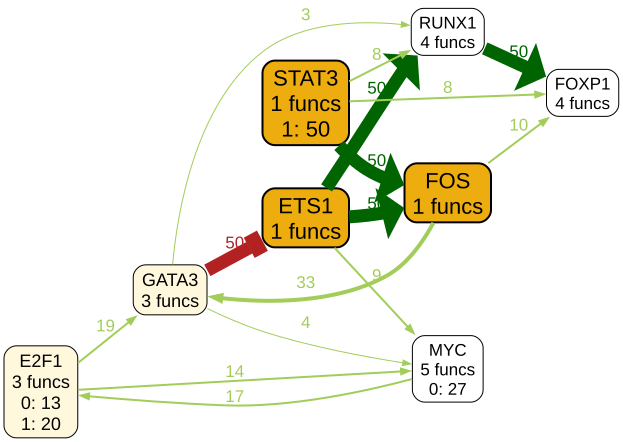


12w: 50 models, 8 genes
Invariant genes: 3
 1 edges present in    3 models
 1 edges present in    4 models
 2 edges present in    8 models
 1 edges present in    9 models
 1 edges present in   10 models
 1 edges present in   14 models
 1 edges present in   17 models
 1 edges present in   19 models
 1 edges present in   33 models
 5 edges present in   50 models
Saved to: ../Results/Ensemble_analysis_Tcell_12w_vs_17w/12w

---- 17 PCW SCC ensemble ----


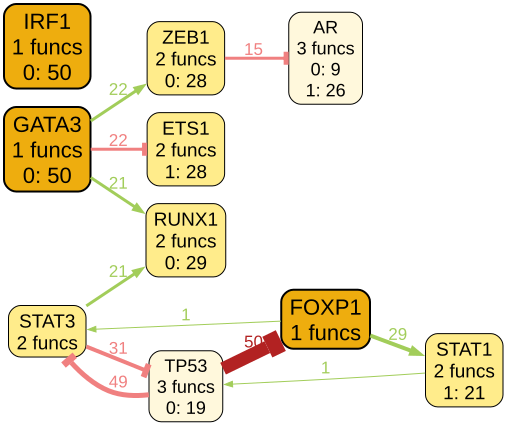


17w: 50 models, 10 genes
Invariant genes: 3
 2 edges present in    1 models
 1 edges present in   15 models
 2 edges present in   21 models
 2 edges present in   22 models
 1 edges present in   29 models
 1 edges present in   31 models
 1 edges present in   49 models
 1 edges present in   50 models
Saved to: ../Results/Ensemble_analysis_Tcell_12w_vs_17w/17w


,model_count,gene_count,week,source,signed_edge_count,invariant_gene_count,sampling_complete,requested_models
week,,,,,,,,
12w,50,8,12w,../Results/Boolean_network_sampling_Tcell_12w_...,15,3,True,50
17w,50,10,17w,../Results/Boolean_network_sampling_Tcell_12w_...,11,3,True,50


Week-specific results: /home/eren/Eren_run/Case_study_2/Results/Ensemble_analysis_Tcell_12w_vs_17w


In [6]:
SUMMARIES = {}
for week in WEEKS:
    print(f'\n---- {LABELS[week]} SCC ensemble ----')
    SUMMARIES[week] = save_ensemble_results(STATS[week], OUTPUT_ROOT / week)

summary_df = pd.DataFrame.from_dict(SUMMARIES, orient='index').rename_axis('week')
summary_df['sampling_complete'] = [ENSEMBLES[week]['complete'] for week in summary_df.index]
summary_df['requested_models'] = [ENSEMBLES[week]['requested'] for week in summary_df.index]
summary_df.to_csv(OUTPUT_ROOT / 'ensemble_interactiongraph_summary.csv')
display(summary_df)
print('Week-specific results:', OUTPUT_ROOT.resolve())

## 7. Cross-week comparison on shared SCC genes and permitted signed edges

In [8]:
def prior_signed_edges(path):
    df = pd.read_csv(path, sep=r'\s+', header=None, comment='#', dtype=str)
    if df.shape[1] != 3:
        raise ValueError(f'Expected three-column signed SIF: {path}')
    return {(str(src).upper(), str(dst).upper(), str(sign))
            for src, sign, dst in df.itertuples(index=False, name=None)}

shared_genes = sorted(set(STATS['12w']['genes']) & set(STATS['17w']['genes']))
gene_rows = []
for gene in shared_genes:
    gene_rows.append({
        'gene': gene,
        '12w_distinct_functions': len(STATS['12w']['functions'][gene]),
        '17w_distinct_functions': len(STATS['17w']['functions'][gene]),
        '12w_invariant': len(STATS['12w']['functions'][gene]) == 1,
        '17w_invariant': len(STATS['17w']['functions'][gene]) == 1,
        '12w_constant_fraction': sum(STATS['12w']['constants'][gene].values()) / STATS['12w']['n_models'],
        '17w_constant_fraction': sum(STATS['17w']['constants'][gene].values()) / STATS['17w']['n_models'],
    })
shared_gene_df = pd.DataFrame(gene_rows, columns=[
    'gene', '12w_distinct_functions', '17w_distinct_functions', '12w_invariant',
    '17w_invariant', '12w_constant_fraction', '17w_constant_fraction',
])
shared_gene_df.to_csv(OUTPUT_ROOT / 'shared_SCC_gene_function_comparison.csv', index=False)

allowed = {}
for week in WEEKS:
    path = COMPONENT_ROOT / week / 'synthesis_core_network.sif'
    if not path.is_file():
        raise FileNotFoundError(f'{week}: required SCC SIF for fair signed-edge comparison: {path}')
    allowed[week] = prior_signed_edges(path)
shared_edges = sorted(allowed['12w'] & allowed['17w'])
edge_rows = []
for source, target, sign in shared_edges:
    positive = sign == '1'
    n12 = STATS['12w']['influences'][target][source][positive]
    n17 = STATS['17w']['influences'][target][source][positive]
    p12 = 100*n12/STATS['12w']['n_models']
    p17 = 100*n17/STATS['17w']['n_models']
    edge_rows.append({
        'source': source, 'target': target,
        'influence': 'activation' if positive else 'inhibition',
        '12w_n_models': n12, '12w_percent_models': round(p12, 2),
        '17w_n_models': n17, '17w_percent_models': round(p17, 2),
        '17w_minus_12w_percentage_points': round(p17-p12, 2),
    })
edge_comparison = pd.DataFrame(edge_rows, columns=[
    'source', 'target', 'influence', '12w_n_models', '12w_percent_models',
    '17w_n_models', '17w_percent_models', '17w_minus_12w_percentage_points',
])
edge_comparison.to_csv(OUTPUT_ROOT / 'shared_prior_edge_frequency_comparison.csv', index=False)

print(f'Shared SCC genes: {len(shared_genes)}; signed edges available in both priors: {len(shared_edges)}')
display(shared_gene_df)
display(edge_comparison)

Shared SCC genes: 5; signed edges available in both priors: 10


,gene,12w_distinct_functions,17w_distinct_functions,12w_invariant,17w_invariant,12w_constant_fraction,17w_constant_fraction
0,ETS1,1,2,True,False,0.0,0.56
1,FOXP1,4,1,False,True,0.0,0.00
2,GATA3,3,1,False,True,0.0,1.00
3,RUNX1,4,2,False,False,0.0,0.58
4,STAT3,1,2,True,False,1.0,0.00


,source,target,influence,12w_n_models,12w_percent_models,17w_n_models,17w_percent_models,17w_minus_12w_percentage_points
0,ETS1,GATA3,activation,0,0.0,0,0.0,0.0
1,ETS1,RUNX1,activation,50,100.0,0,0.0,-100.0
2,FOXP1,STAT3,activation,0,0.0,1,2.0,2.0
3,GATA3,ETS1,inhibition,50,100.0,22,44.0,-56.0
4,GATA3,RUNX1,activation,3,6.0,21,42.0,36.0
5,RUNX1,ETS1,activation,0,0.0,0,0.0,0.0
6,RUNX1,FOXP1,activation,50,100.0,0,0.0,-100.0
7,RUNX1,STAT3,activation,0,0.0,0,0.0,0.0
8,STAT3,FOXP1,activation,8,16.0,0,0.0,-16.0
9,STAT3,RUNX1,activation,8,16.0,21,42.0,26.0
